# filter tracks
- input: linked cell features from 51_
- for ICON and OBS for June and December 2023 data
- 2 types of filter
    - quality control => **valid tracks**
      - tracks never growing >2
    - physically founded/ interest **filtered tracks**
      - lifetime >12 hours
- gives statistics about lost rain amount compared to the domain 
- output:
    - linking/valid (passing quality control)
    - linking/filtered (passing quality control and lifetime filter) => final tracks used

## load packages

In [1]:
import warnings

# ignore general categories
for cat in [FutureWarning, RuntimeWarning, UserWarning]:
    warnings.filterwarnings("ignore", category=cat)

# ignore specific repeated messages
for msg in [
    "pyproj unable to set PROJ database path",
    "As of v1.6.0, segmentation with time length 1",
    "Using DEFAULT_SPHERICAL_EARTH_RADIUS"
]:
    warnings.filterwarnings("ignore", message=msg)


import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

# Import tobac itself:
import sys


# own plotting functions
sys.path.append("../tools")
import plots_mapping as pm
import plots_figures as figs

# plotting
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


## arguments

In [2]:
inputdir = "../output/linking/raw"
models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]

# valid tracks
savedir_valid = Path("../output/linking/valid")
savedir_valid.mkdir(parents=True, exist_ok=True)

# filtered tracks 
savedir_filtered = Path("../output/linking/filtered")
savedir_filtered.mkdir(parents=True, exist_ok=True)


plotsdir =  Path(f"../output/plots/linking")
plotsdir.mkdir(parents=True, exist_ok=True)


domain_area_m2 = 255032272355328.0

## load data

In [3]:
## load tracks
ds = {}
for model in models: 
    ds[model] = {}
    for timeperiod in timeperiods: 
        file = os.path.join(inputdir,f"all_tracks_{model}_{timeperiod}.h5")
        Tracks = pd.read_hdf(file, key='table') 
        
        Tracks["rain_amount"] =  (3 * Tracks["mean_precip_cell"] * Tracks["area_cell"] )  # mm m2 

        ds[model][timeperiod] = Tracks

In [4]:
ds["ICON"]["JUNE"]

,frame,idx_cell,hdim_1,hdim_2,num_cell,threshold_value_cell,feature,time,timestr,latitude,...,mean_precip_anvil,total_precip_anvil,max_precip_anvil,total_dtiwp_anvil,cell,time_cell,track,time_track,v,rain_amount
0,0,1,0.551867,1531.033406,16,10,1,2023-06-01 00:00:00,2023-06-01 00:00:00,-29.894812,...,2.974493,1674.639526,29.634851,218.724091,1,0 days 00:00:00,1,0 days 00:00:00,NaN,5.935243e+10
1,0,924,383.511913,268.670733,8,10,924,2023-06-01 00:00:00,2023-06-01 00:00:00,8.401191,...,1.419240,229.916962,32.860954,14.107671,2,0 days 00:00:00,2,0 days 00:00:00,8.266605,6.621252e+10
2,0,916,381.000000,138.950216,3,10,916,2023-06-01 00:00:00,2023-06-01 00:00:00,8.150000,...,2.238765,709.688599,34.753746,78.84996,3,0 days 00:00:00,3,0 days 00:00:00,NaN,1.616408e+10
3,0,910,381.222012,2599.264569,14,10,910,2023-06-01 00:00:00,2023-06-01 00:00:00,8.172201,...,2.723440,272.344025,19.457909,37.972752,4,0 days 00:00:00,4,0 days 00:00:00,1.086752,6.832463e+10
4,0,907,381.610365,1480.710365,12,10,907,2023-06-01 00:00:00,2023-06-01 00:00:00,8.211036,...,2.294892,279.976776,28.562515,40.06966,5,0 days 00:00:00,5,0 days 00:00:00,9.644525,7.920683e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110099,239,418,306.000000,2619.000000,1,10,418,2023-06-30 21:00:00,2023-06-30 21:00:00,0.650000,...,0.771937,207.651031,20.862518,51.335964,51457,0 days 03:00:00,51308,0 days 03:00:00,NaN,5.683738e+09
110100,239,417,306.000000,2617.000000,1,10,417,2023-06-30 21:00:00,2023-06-30 21:00:00,0.650000,...,0.771937,207.651031,20.862518,51.335964,51682,0 days 00:00:00,51533,0 days 00:00:00,NaN,7.730035e+09
110101,239,413,305.316027,2622.601301,4,10,413,2023-06-30 21:00:00,2023-06-30 21:00:00,0.581603,...,0.771937,207.651031,20.862518,51.335964,51683,0 days 00:00:00,51534,0 days 00:00:00,NaN,2.233846e+10
110102,239,462,321.200694,2052.772812,6,10,462,2023-06-30 21:00:00,2023-06-30 21:00:00,2.170069,...,1.103416,1089.071289,37.638271,183.37883,51684,0 days 00:00:00,51535,0 days 00:00:00,NaN,4.902945e+10


# quality filters

In [5]:
# filter 
sizefilter = 2

ds_valid = {}

# for diagnosics 
diag = {model: {} for model in models}
all_max_sizes = {}

for model in models:
    ds_valid[model] = {}
    all_max_sizes[model] = {}
    for timeperiod in timeperiods:
        
        Tracks = ds[model][timeperiod].copy()

        # exclude tracks that never exceed sizefilter pixels
        tracks_max_size = Tracks.groupby("track")["num_cell"].max()
        bad_size_tracks = tracks_max_size[tracks_max_size <= sizefilter].index
       
         # filter
        bad_tracks = bad_size_tracks #.union(bad_velocity_tracks).union(bad_lifetime_tracks)
        ds_valid[model][timeperiod] = Tracks[~Tracks["track"].isin(bad_tracks)]


        # diagnostics     
        total_tracks = Tracks["track"].nunique()
        total_rain = Tracks["rain_amount"].sum() / domain_area_m2 
        
        valid_tracks = ds_valid[model][timeperiod]["track"].nunique()
        valid_rain = ds_valid[model][timeperiod]["rain_amount"].sum() / domain_area_m2 

        def rain_fraction(bad_tracks):
            rain_lost = Tracks.loc[Tracks["track"].isin(bad_tracks), "rain_amount"].sum() / domain_area_m2 
            return 100 * rain_lost / total_rain
             
        print(f"{model} {timeperiod}:\n{total_tracks} tracks in | total rain: {total_rain:.2e} mm")
        print(f"=> {bad_size_tracks.nunique()} never exceeding {sizefilter}px ({rain_fraction(bad_size_tracks):.1f}% of rain)")
        print(f"{valid_tracks} valid tracks remaining ({100*valid_tracks/total_tracks:.1f}%) | valid rain: {valid_rain:.2e} mm ({100*valid_rain/total_rain:.1f}%)\n")

        #  store everything the plotting cell needs 
        diag[model][timeperiod] = {
            "total_tracks": total_tracks,
            "total_rain": total_rain,
            "valid_rain": valid_rain,
            "bad_size": (bad_size_tracks.nunique(), rain_fraction(bad_size_tracks)),
        }
        
        all_max_sizes[model][timeperiod] = tracks_max_size

ICON JUNE:
51535 tracks in | total rain: 2.22e+01 mm
=> 9183 never exceeding 2px (1.3% of rain)
42352 valid tracks remaining (82.2%) | valid rain: 2.19e+01 mm (98.7%)

ICON DECEMBER:
55094 tracks in | total rain: 2.41e+01 mm
=> 9580 never exceeding 2px (1.2% of rain)
45514 valid tracks remaining (82.6%) | valid rain: 2.38e+01 mm (98.8%)

OBS JUNE:
17463 tracks in | total rain: 1.21e+01 mm
=> 5909 never exceeding 2px (1.2% of rain)
11554 valid tracks remaining (66.2%) | valid rain: 1.20e+01 mm (98.8%)

OBS DECEMBER:
17747 tracks in | total rain: 1.36e+01 mm
=> 6002 never exceeding 2px (1.1% of rain)
11745 valid tracks remaining (66.2%) | valid rain: 1.34e+01 mm (98.9%)



# save valid

In [6]:
# for model in models:
#     for timeperiod in timeperiods:
#         ds_valid[model][timeperiod].to_hdf(
#             os.path.join(savedir_valid, f"all_tracks_filtered_{model}_{timeperiod}.h5"),
#             key='table', mode='w')

/tmp/ipykernel_2524314/354431733.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'mean_air_temperature', 'total_dtiwp_cell', 'mean_iwp_cell',
       'total_iwp_cell', 'total_dtiwp_anvil'],
      dtype='object')]

  ds_valid[model][timeperiod].to_hdf(
/tmp/ipykernel_2524314/354431733.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'mean_air_temperature', 'total_dtiwp_cell', 'mean_iwp_cell',
       'total_iwp_cell', 'total_dtiwp_anvil'],
      dtype='object')]

  ds_valid[model][timeperiod].to_hdf(
/tmp/ipykernel_2524314/354431733.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block

## bsp plots

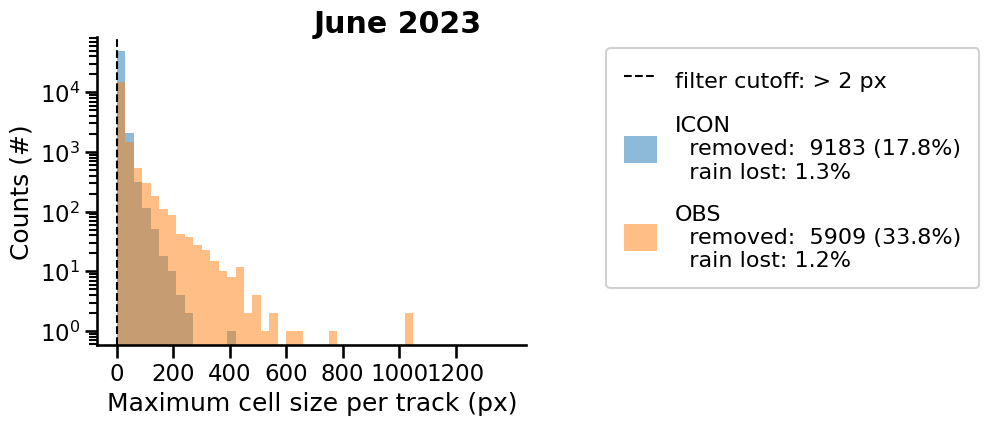

ICON: valid rain retained = 98.7% (total = 2.22e+01 mm, valid = 2.19e+01 mm)
OBS: valid rain retained = 98.8% (total = 1.21e+01 mm, valid = 1.20e+01 mm)


In [7]:
sns.set_context("talk")
dt = 10800
dt_h = dt / 3600
timeperiod = "JUNE"

#  pull precomputed diagnostics for this timeperiod 
all_max_sizes_list = [all_max_sizes[model][timeperiod] for model in models]
diag_tp = {model: diag[model][timeperiod] for model in models}

#  shared bin edges 
max_size_val = max(ms.max() for ms in all_max_sizes_list)
size_bin_edges = np.arange(0.5, min(max_size_val, max_size_val) + 1.5, 30)

#  layout: single panel + info panel 
fig = plt.figure(figsize=(8, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[3.5, 1], wspace=0.25)
ax_hist = fig.add_subplot(gs[0])
ax_info = fig.add_subplot(gs[1])

#  size 
for model, ms in zip(models, all_max_sizes_list):
    ax_hist.hist(ms, bins=size_bin_edges, density=False, alpha=0.5, label=model)
ax_hist.axvline(sizefilter + 0.5, color='k', linestyle='--', linewidth=1.5)
ax_hist.set_xlabel('Maximum cell size per track (px)')
ax_hist.set_ylabel('Counts (#)')
ax_hist.set_yscale('log')
#ax_hist.set_xscale("log")
#ax_hist.set_title('Maximum Track Size', fontweight='bold')
ax_hist.set_xticks(range(0, max_size_val, 200))

#  custom combined legend+stats in info panel 
fkey = 'bad_size'
flabel = f'cutoff: > {sizefilter} px'

ax_info.axis('off')
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
handles = []
labels = []
# cutoff line entry
handles.append(Line2D([0], [0], color='k', linestyle='--', linewidth=1.5))
labels.append(f'filter {flabel}')
# one entry per model: color patch + stats as label
for j, model in enumerate(models):
    n, pct = diag_tp[model][fkey]
    total = diag_tp[model]['total_tracks']
    handles.append(Patch(facecolor=color_cycle[j], alpha=0.5))
    labels.append(
        f"{model}\n"
        f"  removed:  {n} ({100*n/total:.1f}%)\n"
        f"  rain lost: {pct:.1f}%"
    )
ax_info.legend(
    handles, labels,
    loc='upper left',
    frameon=True,
    fontsize=16,
    title_fontsize=16,
    borderpad=0.8,
    labelspacing=1.0,
    handlelength=1.5,
    handleheight=1.5,
    framealpha=0.9,
)

sns.despine(fig=fig)
fig.suptitle('June 2023', fontweight='bold', y = 0.95)
plt.savefig(os.path.join(plotsdir, "invalid_qc_filter_diagnostics_JUNE.pdf"), bbox_inches='tight')
plt.show()

#  sanity check / caption numbers 
for model in models:
    d = diag_tp[model]
    print(f"{model}: valid rain retained = {100*d['valid_rain']/d['total_rain']:.1f}% "
          f"(total = {d['total_rain']:.2e} mm, valid = {d['valid_rain']:.2e} mm)")

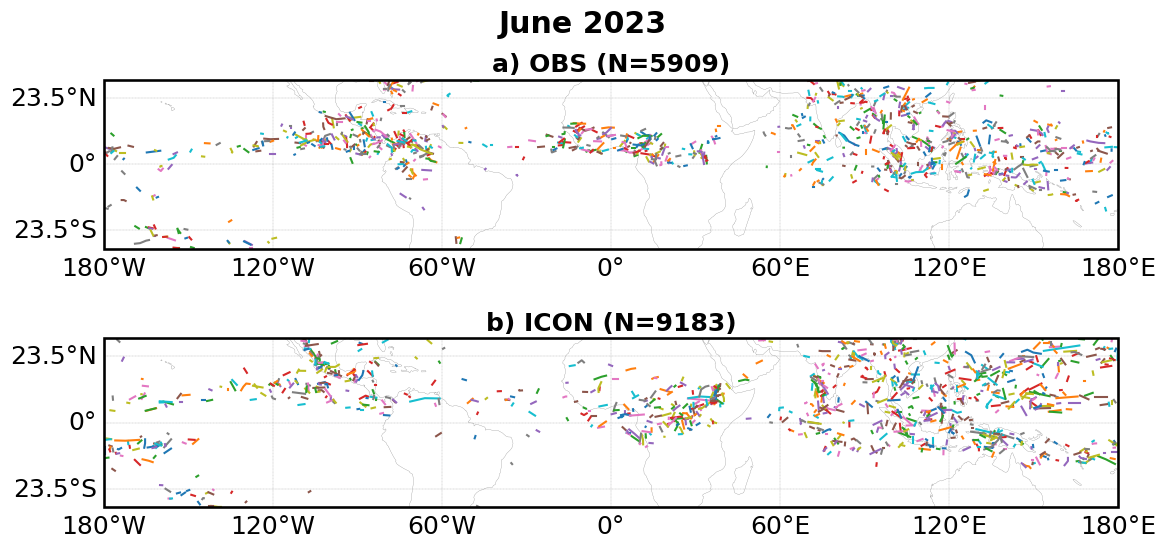

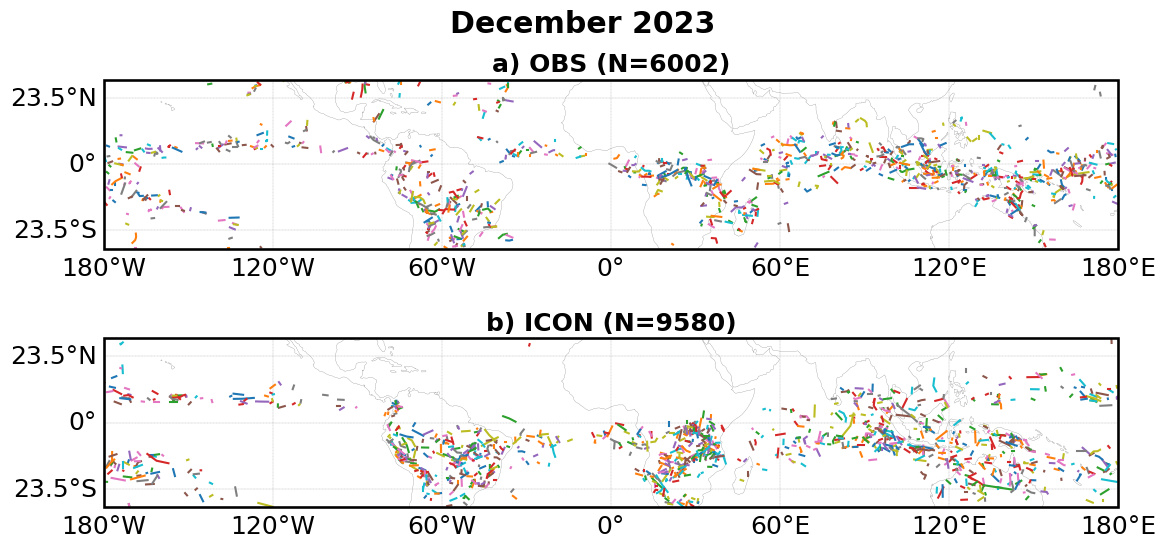

In [8]:
for timeperiod in ["JUNE", "DECEMBER"]:
    fig, axes = plt.subplots(len(models), 1, figsize=(12, 3*len(models)),
                              subplot_kw={'projection': ccrs.PlateCarree()})
    if len(models) == 1:
        axes = [axes]

    panel_letters = ['a', 'b', 'c', 'd']  # extend if needed

    models_sorted = ["OBS","ICON"]
    for ax, model, letter in zip(axes, models_sorted, panel_letters):
        Tracks = ds[model][timeperiod].copy()

        #  identify filtered tracks 
        tracks_max_size = Tracks.groupby("track")["num_cell"].max()
        bad_size_ids = tracks_max_size[tracks_max_size <= sizefilter].index
        bad_s = Tracks[Tracks["track"].isin(bad_size_ids)]

        subtitle = f"{letter}) {model} (N={bad_size_ids.nunique()})"

        pm.domain_plot_cells(bad_s, "track", title=subtitle, fig=fig, ax=ax)

    month_label = "June 2023" if timeperiod == "JUNE" else "December 2023"
    fig.suptitle(f"{month_label}", fontweight="bold", y = 0.93) #Maximum Size ≤ {sizefilter} px - 
    plt.tight_layout()
    plt.savefig(os.path.join(plotsdir, f"invalid_qc_filter_maps_{timeperiod}.pdf"), bbox_inches="tight")
    plt.show()

# physical filters

In [9]:
hourfilter = "12"
ds_long = {}
for model in models:
    ds_long[model] = {}
    for timeperiod in timeperiods:
        
        Tracks = ds_valid[model][timeperiod]
        
        lifetime = Tracks.groupby("track")["time_track"].max()
        long_lived_cells = lifetime[lifetime >= pd.Timedelta(f"{hourfilter}h")].index
        ds_long[model][timeperiod] = Tracks[Tracks["track"].isin(long_lived_cells)]
        
        # diagnostics
        total_tracks = Tracks["track"].nunique()
        total_rain = Tracks["rain_amount"].sum() / domain_area_m2 
        valid_cells = ds_long[model][timeperiod]["track"].nunique()
        valid_rain = ds_long[model][timeperiod]["rain_amount"].sum() / domain_area_m2 
        
        print(f"{model} {timeperiod}: {total_tracks} tracks in => {valid_cells} cells ≥{hourfilter}h ({100*valid_cells/total_tracks:.1f}%) | rain kept: {valid_rain:.2e} mm ({100*valid_rain/total_rain:.1f}%)")

ICON JUNE: 42352 tracks in => 4605 cells ≥12h (10.9%) | rain kept: 8.33e+00 mm (38.0%)
ICON DECEMBER: 45514 tracks in => 4825 cells ≥12h (10.6%) | rain kept: 8.71e+00 mm (36.6%)
OBS JUNE: 11554 tracks in => 1132 cells ≥12h (9.8%) | rain kept: 5.58e+00 mm (46.5%)
OBS DECEMBER: 11745 tracks in => 1160 cells ≥12h (9.9%) | rain kept: 6.07e+00 mm (45.2%)


# save selected

In [10]:
for model in models:
    for timeperiod in timeperiods:
        ds_long[model][timeperiod].to_hdf(
            os.path.join(savedir_filtered, f"all_tracks_filtered_{model}_{timeperiod}.h5"),
            key='table', mode='w'
        )

/tmp/ipykernel_2524314/2328525967.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'mean_air_temperature', 'total_dtiwp_cell', 'mean_iwp_cell',
       'total_iwp_cell', 'total_dtiwp_anvil'],
      dtype='object')]

  ds_long[model][timeperiod].to_hdf(
/tmp/ipykernel_2524314/2328525967.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'mean_air_temperature', 'total_dtiwp_cell', 'mean_iwp_cell',
       'total_iwp_cell', 'total_dtiwp_anvil'],
      dtype='object')]

  ds_long[model][timeperiod].to_hdf(
/tmp/ipykernel_2524314/2328525967.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->bloc

# plot some stuff 

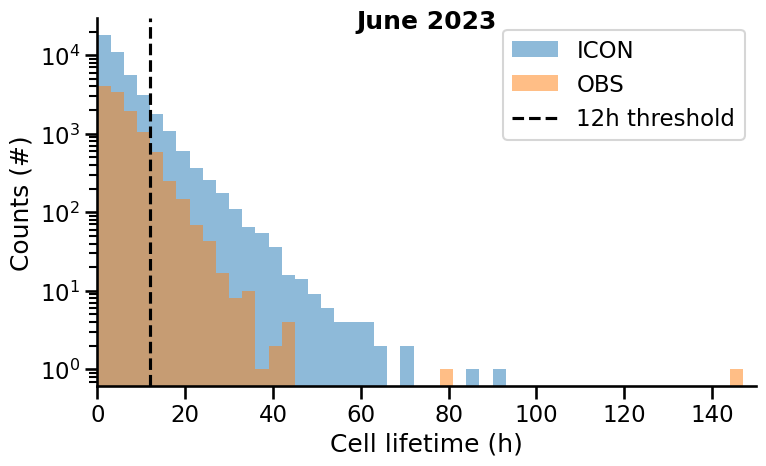

In [11]:
import numpy as np
sns.set_context("talk")
maxlifebinedge = 200
bin_edges = np.arange(0- 0.01, maxlifebinedge, 3)

fig, ax = plt.subplots(figsize=(8, 5))
for model in models:
    Tracks = ds_valid[model]["JUNE"]
    lifetime = Tracks.groupby("track")["time_track"].max()
    lifetime_hours = lifetime.dt.total_seconds() / 3600
    ax.hist(lifetime_hours, bins=bin_edges, density=False, alpha=0.5, label=model)

ax.axvline(int(hourfilter), color='k', linestyle='--', label=f"{hourfilter}h threshold")
ax.set_xlabel("Cell lifetime (h)")
ax.set_ylabel("Counts (#)")
ax.set_title("June 2023", fontweight = "bold", y =0.95) #ell Lifetimes Valid Tracks - 
ax.set_xlim(0, 150)
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
sns.despine()
plt.savefig(os.path.join(plotsdir, "filtered_selected_lifetimes_histo_JUNE_2023.pdf"), bbox_inches='tight')
plt.show()

## Plot filtered

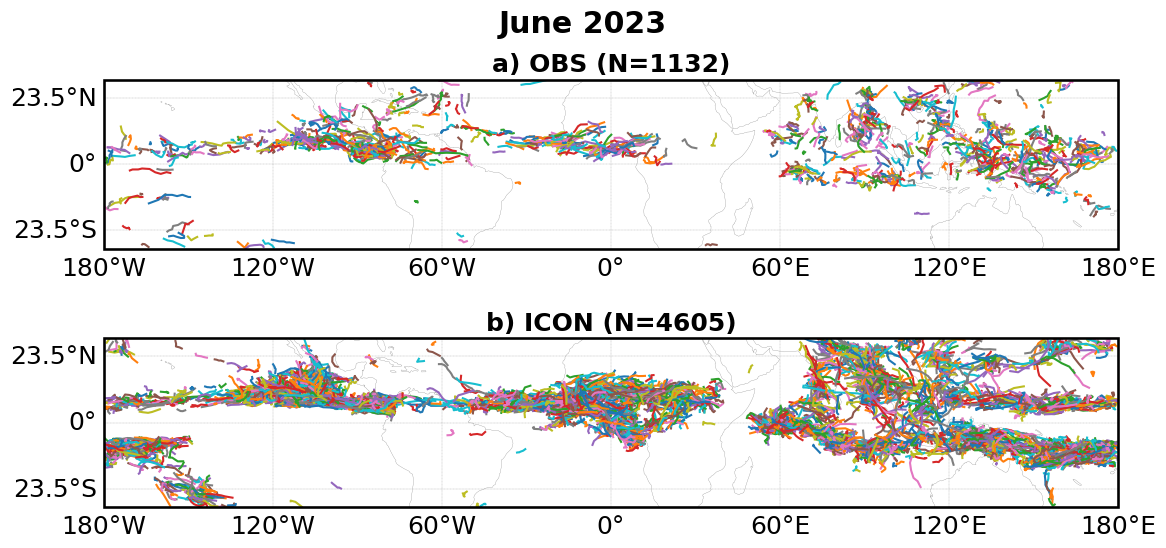

In [12]:

selected_obs = ds_long["OBS"]["JUNE"]
selected_icon = ds_long["ICON"]["JUNE"]


fig, axes = plt.subplots(2, 1, figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

pm.domain_plot_cells(selected_obs, "track", title=f"a) OBS (N={len(np.unique(selected_obs.track))})", fig=fig, ax=axes[0])
pm.domain_plot_cells(selected_icon,"track", title=f"b) ICON (N={len(np.unique(selected_icon.track))})",fig=fig, ax=axes[1])

fig.suptitle(f"June 2023", fontweight = "bold", y = 0.93)
plt.tight_layout()
plt.savefig(os.path.join(plotsdir, "track_maps_filtered_cells_JUNE_2023.pdf"), bbox_inches='tight')
plt.show()

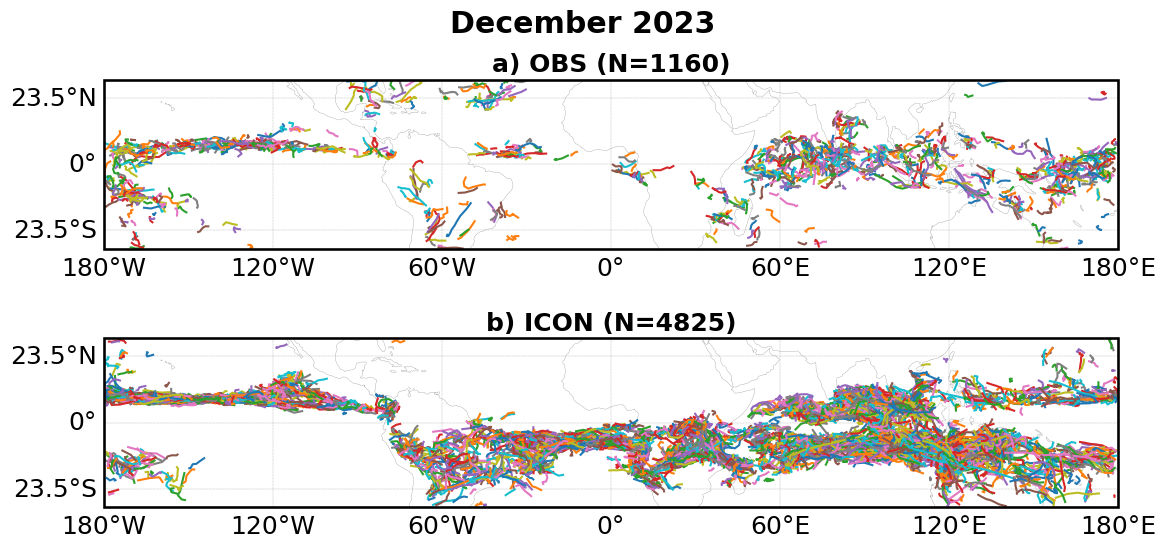

In [13]:

selected_obs = ds_long["OBS"]["DECEMBER"]
selected_icon = ds_long["ICON"]["DECEMBER"]


fig, axes = plt.subplots(2, 1, figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

pm.domain_plot_cells(selected_obs, "track", title=f"a) OBS (N={len(np.unique(selected_obs.track))})", fig=fig, ax=axes[0])
pm.domain_plot_cells(selected_icon,"track", title=f"b) ICON (N={len(np.unique(selected_icon.track))})",fig=fig, ax=axes[1])

fig.suptitle(f"December 2023", fontweight = "bold", y = 0.93)
plt.tight_layout()
plt.savefig(os.path.join(plotsdir, "track_maps_filtered_cells_DECEMBER_2023.pdf"), bbox_inches='tight')
plt.show()

# some further exploratiosn

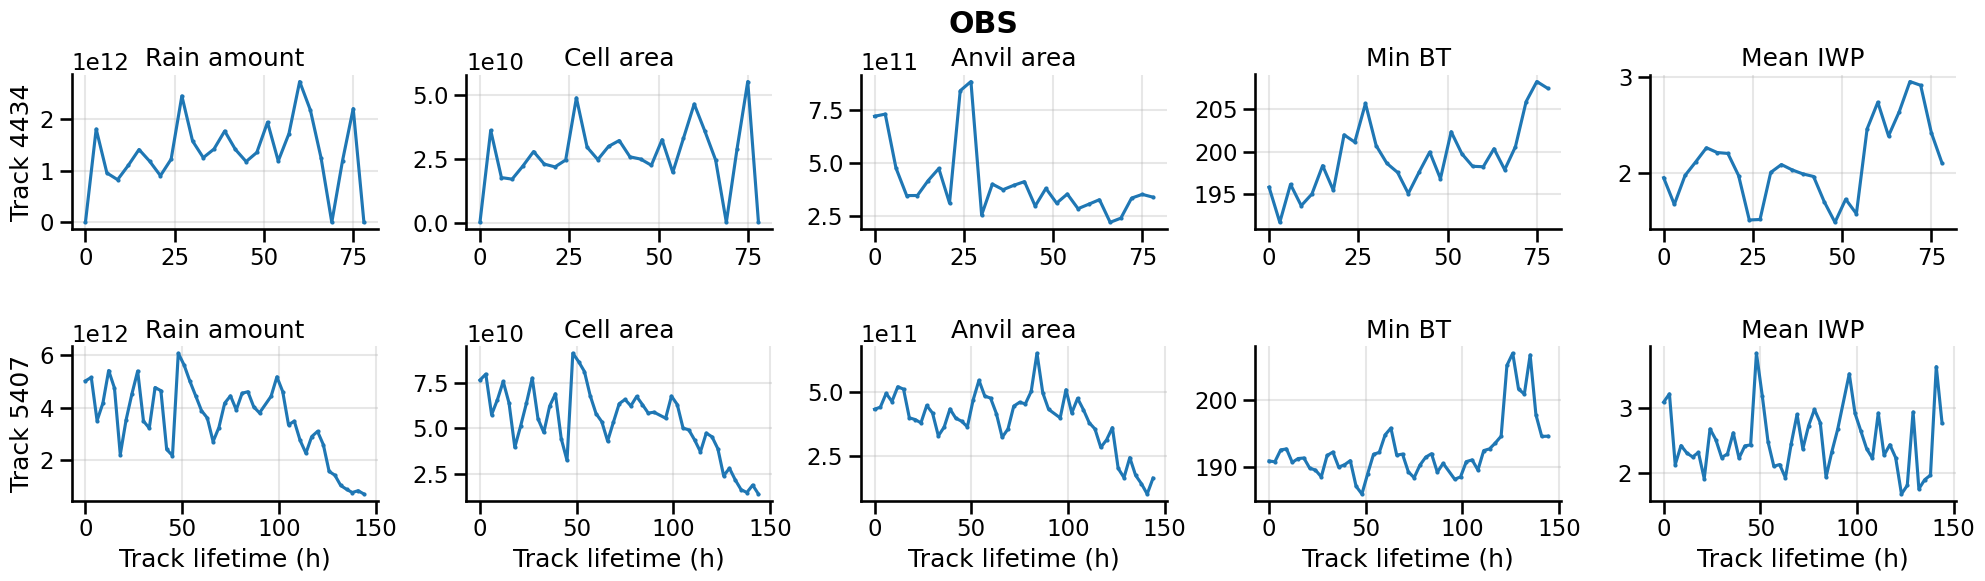

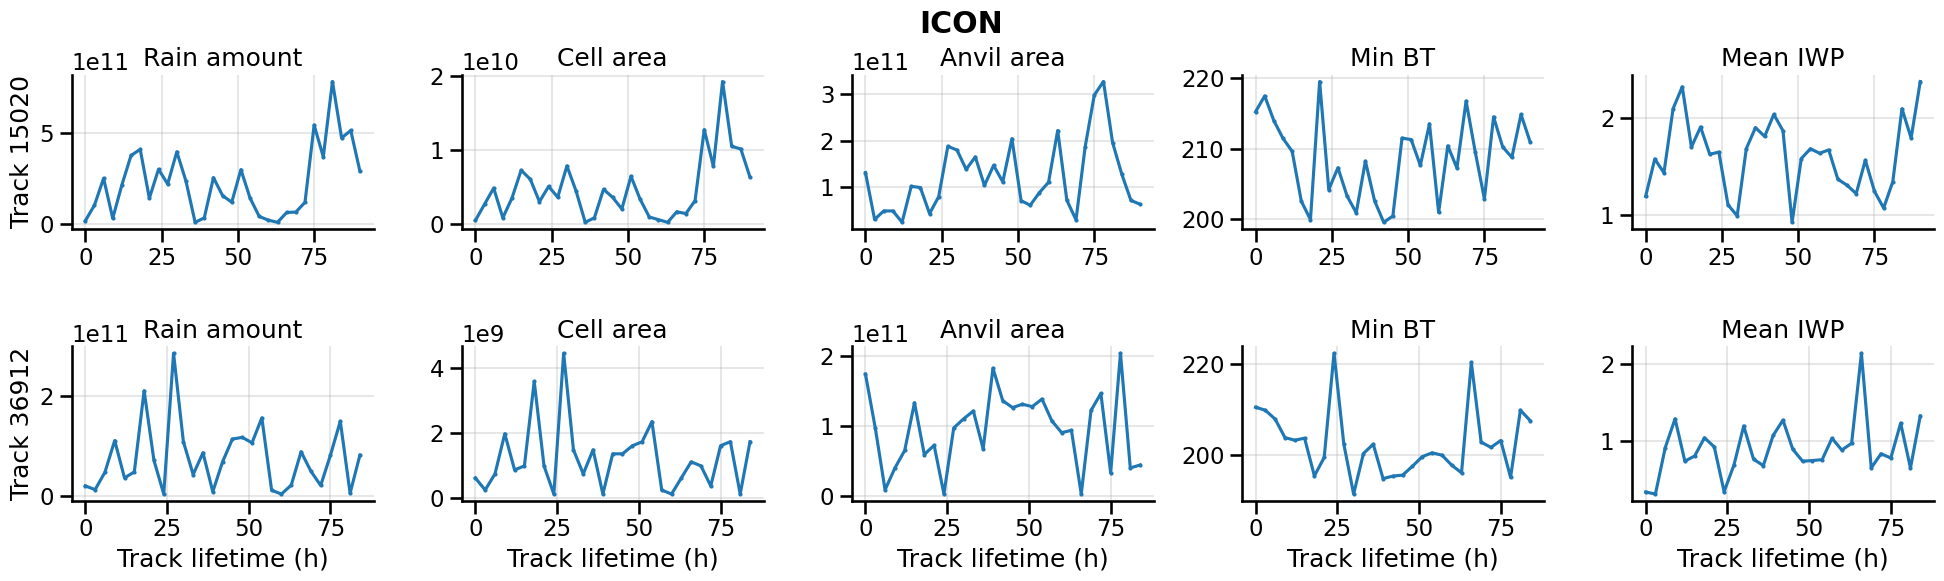

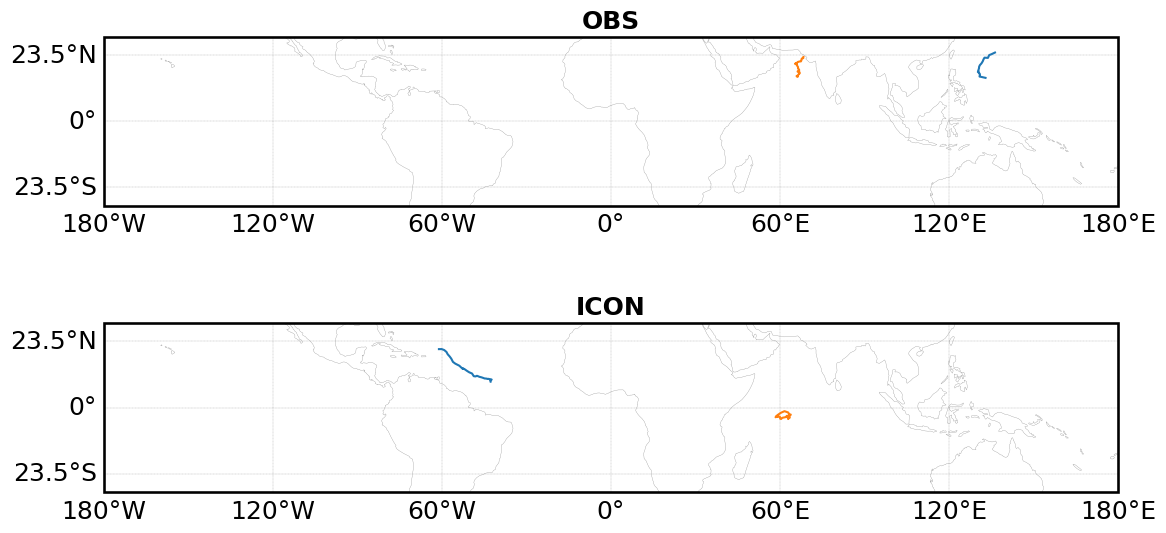

In [14]:
lifetime_max = 72

Tracks = ds_long["OBS"]["JUNE"]
lifetime = Tracks.groupby("track")["time_track"].max()
bad_lifetime_idx = lifetime[lifetime > pd.Timedelta(f"{lifetime_max}h")].index
badlifetime_obs = Tracks[Tracks["track"].isin(bad_lifetime_idx)]

Tracks = ds_long["ICON"]["JUNE"]
lifetime = Tracks.groupby("track")["time_track"].max()
bad_lifetime_idx = lifetime[lifetime > pd.Timedelta(f"{lifetime_max}h")].index
badlifetime_icon = Tracks[Tracks["track"].isin(bad_lifetime_idx)]



figs.quick_lifetime_plot_tracks(badlifetime_obs,title = "OBS")

figs.quick_lifetime_plot_tracks(badlifetime_icon, title = "ICON")



###################
#############

fig, axes = plt.subplots(2, 1, figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

pm.domain_plot_cells(badlifetime_obs, "track", title=f"OBS", fig=fig, ax=axes[0])
pm.domain_plot_cells(badlifetime_icon, "track", title=f"ICON", fig=fig, ax=axes[1])

plt.tight_layout()
plt.show()

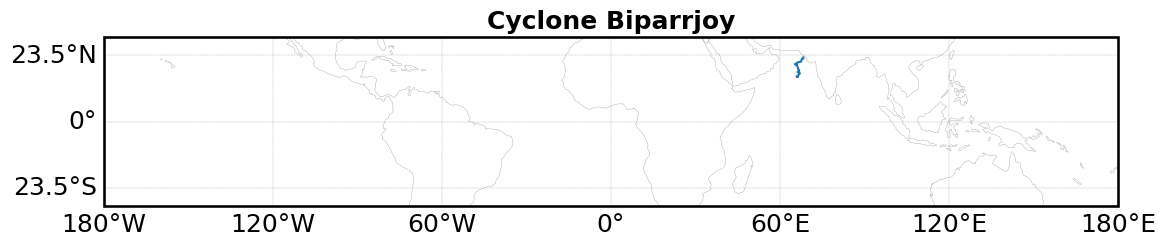

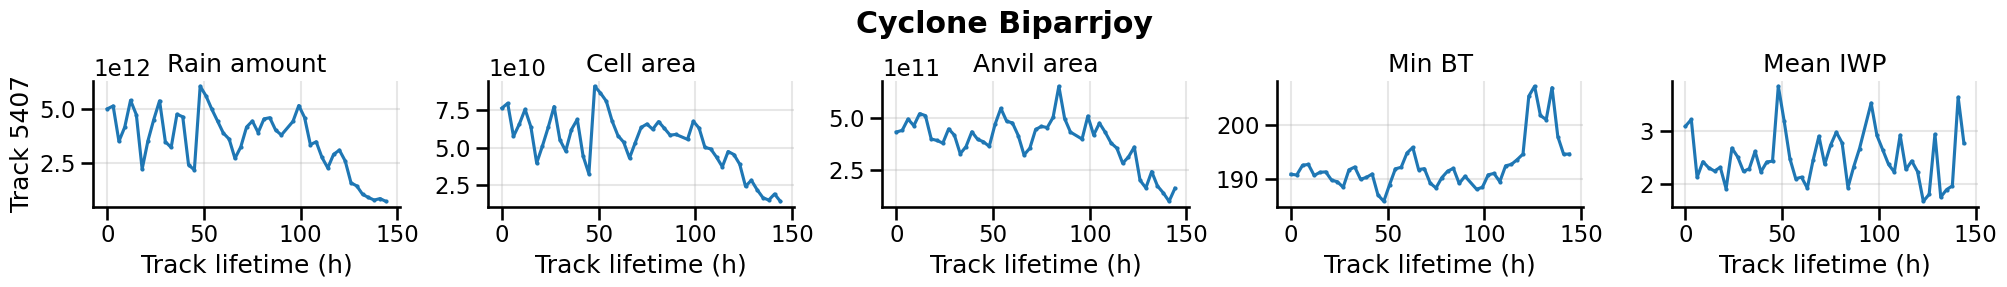

In [15]:
Tracks = ds_long["OBS"]["JUNE"]
biparrjoy = Tracks[Tracks["track"].isin([5407])]

pm.domain_plot_cells(biparrjoy, "track", title=f"Cyclone Biparrjoy")

figs.quick_lifetime_plot_tracks(biparrjoy,title = "Cyclone Biparrjoy")


In [16]:
Tracks = ds_long["OBS"]["JUNE"]
biparrjoy = Tracks[Tracks["track"].isin([4434])]
biparrjoy

,frame,idx_cell,hdim_1,hdim_2,num_cell,threshold_value_cell,feature,time,timestr,latitude,...,mean_precip_anvil,total_precip_anvil,max_precip_anvil,total_dtiwp_anvil,cell,time_cell,track,time_track,v,rain_amount
8803,58,128,453.136936,3129.448583,3,10,128,2023-06-08 06:00:00,2023-06-08 06:00:00,15.363693,...,2.056100,12322.208984,27.635000,907.680359,4454,0 days 00:00:00,4434,0 days 00:00:00,16.577388,7.774333e+09
8890,59,111,456.750735,3113.181436,303,10,111,2023-06-08 09:00:00,2023-06-08 09:00:00,15.725073,...,2.189371,13289.484375,32.448334,689.426086,4454,0 days 03:00:00,4434,0 days 03:00:00,5.193082,1.807800e+12
9014,60,147,457.701078,3108.039960,148,10,147,2023-06-08 12:00:00,2023-06-08 12:00:00,15.820107,...,2.363700,9428.798828,32.266666,491.457611,4454,0 days 06:00:00,4434,0 days 06:00:00,2.197306,9.585140e+11
9222,61,150,459.630223,3108.983323,144,10,150,2023-06-08 15:00:00,2023-06-08 15:00:00,16.013022,...,2.685293,7806.146484,30.418335,171.85817,4454,0 days 09:00:00,4434,0 days 09:00:00,1.417541,8.283600e+11
9390,62,163,461.002645,3108.890808,187,10,162,2023-06-08 18:00:00,2023-06-08 18:00:00,16.150264,...,3.581882,10426.858398,33.878330,493.62085,4454,0 days 12:00:00,4434,0 days 12:00:00,1.638196,1.105672e+12
9561,63,161,462.589836,3108.977523,234,10,161,2023-06-08 21:00:00,2023-06-08 21:00:00,16.308984,...,3.551470,12423.042969,34.936665,756.478821,4454,0 days 15:00:00,4434,0 days 15:00:00,2.800588,1.412455e+12
9726,64,178,465.243991,3109.583947,193,10,178,2023-06-09 00:00:00,2023-06-09 00:00:00,16.574398,...,3.357966,13368.064453,31.816668,908.664429,4454,0 days 18:00:00,4434,0 days 18:00:00,2.781579,1.183966e+12
9893,65,143,467.805775,3108.698002,185,10,143,2023-06-09 03:00:00,2023-06-09 03:00:00,16.830578,...,2.478721,6486.812012,19.049999,356.123596,4454,0 days 21:00:00,4434,0 days 21:00:00,3.672927,9.057601e+11
10039,66,160,470.038732,3105.794887,208,10,160,2023-06-09 06:00:00,2023-06-09 06:00:00,17.053872,...,1.748725,12291.785156,30.188334,1107.632812,4454,1 days 00:00:00,4434,1 days 00:00:00,2.014324,1.225765e+12
10159,67,126,471.853637,3106.553413,414,10,126,2023-06-09 09:00:00,2023-06-09 09:00:00,17.235364,...,1.837871,13589.220703,31.240000,924.725037,4454,1 days 03:00:00,4434,1 days 03:00:00,4.975837,2.448998e+12
